# chip_01_4x4 — sixteen chip_01 dies tiled 4 × 4 (positions fixed), on the Quantcore PDK

## 1 · What the chip is

**Source:** `components/python/chip_01_4x4.py` (writes `wafers/chip_01_4x4.gds`), Quantcore internal: it reads
`chip_01_2x2.gds` — the `DIE` cell that `die_creator.py` makes from one chip, four copies at (±3750, ±3750) µm in a
15 mm die — and inserts that `DIE` into a `WAFER` cell. Spec: `docs/designs/legacy/chip_01.md` (row
`chip_01_4x4.py`); the die is the chip of the notebook `chip_01`.

**Legacy bug (the design decision, "fix positions and rebuild"):** the script inserts the 15 mm `DIE` sixteen times at
only four positions, (±3750, ±3750) µm, four times each: the copies overlap each other by 7.5 mm, and every position
is duplicated. The intended layout is a **4 × 4 array of 7.5 mm chips** (30 × 30 mm): the four `DIE`s at (±7500,
±7500) µm, each once, i.e. the sixteen chip centres at x, y ∈ {−11250, −3750, +3750, +11250} µm.

| | the rebuild keeps (source-faithful) | the Quantcore PDK changes |
|---|---|---|
| the die | chip_01 as rebuilt in its own notebook (saved design `chip_01.json`) | everything that notebook changed: pads `pad_edge` = 100 µm from the die edge, the PDK frame and device ID, the PDK cheese band, `Quantcore Squid` junctions at 45 kΩ, the corrected claws (#8) |
| the tiling | sixteen chips, one `DIE` (2 × 2 chips) per quadrant | the fixed positions (#15): one chip per 7.5 mm site, each once |
| cheese, frame | — | each die carries its own PDK band and frame; neighbouring frames meet at the shared dicing lines |

This notebook is **lighter** than the per-chip ones: the die is not rebuilt step by step here (that is the
`chip_01` notebook); the steps load it, check it, tile it, and export the die's and the tiling's masks. Steps that
do not apply to a tiling say so.

### Rebuilt (2026-11-03)

The notebook was new in that pass: `chip_01_4x4/die.json` is the chip_01 design renamed `chip_01_4x4_die`, and the
notebook tiles its built cell 16 times at the fixed positions (KLayout `CellInstArray`, die pitch 7500 µm) into
`build/legacy_fix/chip_01_4x4.oas`.

### PDK conformance pass (notebooks-legacy, 2026-11-18)

- `chip_01_4x4/die.json` is regenerated from the current `chip_01.json` (chip_01's leg-2 PDK pass: pads at the
  100 µm rule, feedline 5260 µm, PDK band, `Quantcore Squid` × 4). Run the `chip_01` notebook first whenever its
  design changes: this notebook reads `examples/designs/legacy/chip_01.json`.
- The die keeps chip_01's PDK decisions (pads, cheese "auto" → PDK band, centring (0, 0), trilayer junctions); the
  tiling adds none of its own.
- New: the tiled **fab mask** (the die's `export_fab` mask, tiled the same way) next to the tiled layout.
- Educative layout, lighter: setup → the die → its pads → its components → the tiling → DRC → LOM → FEM → iterate
  → export → snapshots.

## 2 · Setup and the Quantcore PDK

The helpers keep the cells short: `_common` (`C`) holds the netlist / LOM / FEM-export / snapshot helpers and
the PDK checks shared by every design notebook; `_legacy` (`L`) maps the legacy PCell parameters onto the
Quantcore cells, draws the legacy reference with the author's own legacy code (read-only), and holds the step
helpers of these notebooks. `LIVE` decides whether the design is pushed to a running KLayout (`QCC_LIVE=0`
for batch runs: nothing reaches KLayout).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                       # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "legacy"))
LIVE = os.environ.get("QCC_LIVE", "1") == "1"       # live KLayout by default; QCC_LIVE=0 for batch runs
import _common as C                                  # netlist / LOM / FEM-export / snapshot / PDK-check helpers
import _legacy as L                                  # legacy frame shift, parameter mapping, legacy reference, steps
import klayout.db as pya
from IPython.display import Image, Markdown, display
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk

ID, OUT = "chip_01_4x4", Path("examples/designs/legacy")

The PDK facts the die was rebuilt with, read from `get_pdk()` (nothing below is typed in by hand). The `chip_01`
notebook applies them (pad rule, junction rule, centring, cheese band); here they are only checked on the die
(steps 4 and 7) and carried into the die's and the tiling's fab masks (step 13).

In [3]:
CHEESE_NOTE = "PDK band (auto) — inherited from the die: chip_01's source has no cheese of its own"
display(Markdown(L.pdk_facts_md(CHEESE_NOTE)))

| PDK item | value |
|---|---|
| PDK | `quantcore_nb_sapphire_v1` (version 3) |
| stack | sapphire, 650 µm, ε_r 10.25; Nb film (sheet metal in the FEM exports, 0.2 µm for the analytic CPW formulas) |
| CPW default | 10 µm centre, 6 µm gap, bends r = 100 µm |
| die frame | L-shaped dicing markers 25 µm wide (250 µm legs, 1000/0), 3 × 3 alignment grids (1001/0) in 500 µm corner squares, design area 100 µm inside the die edge, device ID optional (bottom centre, or beside the pads) |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (the design-area margin) from the die edge, whatever the original did (`edge="auto"`, DRC design warning `pad_edge`) |
| junction rule | Nb/AlOx/Nb trilayer, Δ = 1.4 meV (I_c·R_n = πΔ/2e), R_n 40–50 kΩ (nominal 45), qubits 4–8 GHz; R_n·A 13500 Ω·µm² and C_J 50 fF/µm² assumed; cells `Quantcore Junction` / `Quantcore Squid` (DRC design warnings `pdk_rn`, `pdk_fq`: flagged, never retuned) |
| 3/0 keep-out | second-metal etch: routes + 10 µm, components' etch bbox + 24 µm, other 1/0 shapes + 9 µm (filled) |
| cheese rule | 3 rows of 5 µm squares, 20 µm gaps, in a band around the 3/0 keep-outs; **the original design's own cheese wins** (chip `cheese`: `"auto"` / `"pdk"` / `"original"`). This chip: PDK band (auto) — inherited from the die: chip_01's source has no cheese of its own |

## 3 · The die and the frame

The die is chip_01's saved design (`Designer.load`, with `autosave=False` and its own layout file, so nothing is
written back to `chip_01.json` or `build/chip_01.oas`), renamed `chip_01_4x4_die` and saved as
`chip_01_4x4/die.json`: the JSON every later step reads. Its chip parameters carry chip_01's choices (device ID,
`cheese` left at `"auto"`, so the build draws the PDK band). The PDK frame (L dicing markers, alignment grids,
boundary, device ID) is drawn on every die.

(0.0, 0.0, 7500.0, 7500.0) quantcore_nb_sapphire_v1 {'with_grid': False, 'name_chip': 'CHIP01 V0'} → examples\designs\legacy\chip_01_4x4\die.json


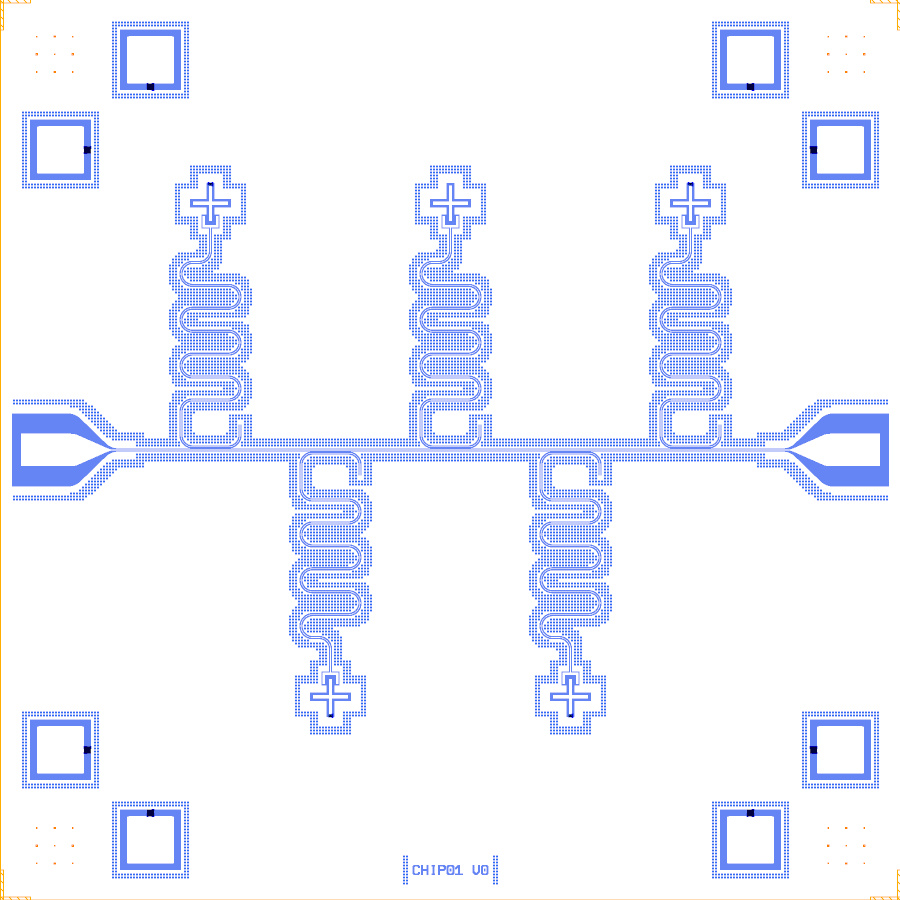

WindowsPath('build/legacy_steps/chip_01_4x4_die_1_die.png')

In [4]:
d = Designer.load(OUT / "chip_01.json", live=LIVE, autosave=False,   # the rebuilt chip_01 (see that notebook);
                  out=Path("build") / "chip_01_4x4_die.oas")      # never written back to chip_01.json / chip_01.oas
d.data["name"] = "chip_01_4x4_die"
(OUT / ID).mkdir(exist_ok=True)
DESIGN = d.save(OUT / ID / "die.json")
print(d.design.chip.box, d.design.pdk, d.design.chip.params, "→", DESIGN)
L.step_snapshot(d, "1_die")

## 4 · Pads (PDK pad rule)

The die's pads come from chip_01: the left pad was placed with `edge="auto"` (outer etch `get_pdk().frame.pad_edge`
= 100 µm from the die edge), the feedline snapped onto it and the right pad onto the feedline. Nothing to move here;
`L.edge_gaps` checks it on the built die.

In [5]:
print("pad etch → die edge (µm):", L.edge_gaps(d), "| rule:", get_pdk().frame.pad_edge)

pad etch → die edge (µm): {'PL': 100.0, 'PR': 100.0} | rule: 100.0


## 5 · Components

Also chip_01's: five `CoupledResonator` λ/4s (5000 µm) on the feedline, five `Xmon`s snapped with their claw tips
onto the resonator ends (#8), four with the PDK **`Quantcore Squid`** sized by the rule (45 kΩ in parallel), the
centre one without a junction, and eight `JunctionGroundPad` test pads. The table counts the die's instances per
cell; the `chip_01` notebook explains each.

In [6]:
from collections import Counter
cells_ = Counter(spec["cell"] for spec in d.data["instances"].values())
display(Markdown("| cell | instances |\n|---|---|\n" + "\n".join(f"| `{k}` | {v} |" for k, v in cells_.items())))
print("junctions:", {n: (s["params"].get("junction_type"), s.get("junction")) for n, s in d.data["instances"].items()
                     if s["cell"] == "Xmon"})

| cell | instances |
|---|---|
| `ConnectorPad` | 2 |
| `CpwSegment` | 1 |
| `CoupledResonator` | 5 |
| `Xmon` | 5 |
| `JunctionGroundPad` | 8 |

junctions: {'Q1': ('Quantcore Squid', {'Lj_nH': 6.7344, 'Cj_fF': 15.0}), 'Q2': ('Quantcore Squid', {'Lj_nH': 6.7344, 'Cj_fF': 15.0}), 'Q3': ('No Squid', None), 'Q4': ('Quantcore Squid', {'Lj_nH': 6.7344, 'Cj_fF': 15.0}), 'Q5': ('Quantcore Squid', {'Lj_nH': 6.7344, 'Cj_fF': 15.0})}


## 6 · The tiling (no routes: the dies are placed, not connected)

The die has no routes, and the tiling adds none: it is cell placement. The legacy `DIE` (2 × 2 chips at
(±3750, ±3750)) goes at the fixed positions (±7500, ±7500), i.e. one chip per 7.5 mm site. The Designer frame has its
origin at the die's lower-left corner, so a chip centred at (x, y) is inserted at (x − 3750, y − 3750). The die is
built once and its cell inserted sixteen times into a `WAFER` cell (`build/legacy_fix/chip_01_4x4.oas`); the table
compares the legacy insertions with the fixed ones.

In [7]:
# chip_01_4x4.py, legacy frame (µm): DIE = 2 × 2 chips (die_creator.py); WAFER = DIE at ...
DIE_CHIPS = [(3750, 3750), (-3750, 3750), (-3750, -3750), (3750, -3750)]          # die_creator.create_die
LEGACY_DIES = [(3750, 3750), (-3750, 3750), (-3750, -3750), (3750, -3750)] * 4      # as written: 16 × on 4 sites (bug)
FIXED_DIES = [(7500, 7500), (-7500, 7500), (-7500, -7500), (7500, -7500)]          # #15: one DIE per quadrant
CHIPS = sorted({(dx + cx, dy + cy) for dx, dy in FIXED_DIES for cx, cy in DIE_CHIPS})
assert len(CHIPS) == 16 and {x for x, _ in CHIPS} == {-11250, -3750, 3750, 11250}


def tile(cell, layout_dbu, name, path):
    """Insert ``cell`` (its tree copied) at the sixteen chip sites into a WAFER cell and write ``path``."""
    tiled = pya.Layout()
    tiled.dbu = layout_dbu
    die_cell = tiled.create_cell(name)
    die_cell.copy_tree(cell)
    wafer = tiled.create_cell("WAFER")
    for x, y in CHIPS:
        wafer.insert(pya.DCellInstArray(die_cell.cell_index(), pya.DTrans(x - L.W / 2, y - L.H / 2)))
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    tiled.write(str(path))
    return wafer.dbbox()


result = d.show() if d.result is None else d.result                # build the die once
TILED = Path("build/legacy_fix/chip_01_4x4.oas")
print(f"{len(CHIPS)} dies, bbox {tile(result.cell, result.layout.dbu, 'CHIP_01_DIE', TILED)} µm → {TILED}")
rows = ["| | legacy `chip_01_4x4.py` | fixed (#15) |", "|---|---|---|",
        f"| DIE insertions | {len(LEGACY_DIES)} at {len(set(LEGACY_DIES))} distinct sites (±3750, ±3750): overlapping by 7.5 mm, each 4× | "
        f"{len(FIXED_DIES)} at (±7500, ±7500), once each |",
        f"| chip sites | {len({(dx + cx, dy + cy) for dx, dy in LEGACY_DIES for cx, cy in DIE_CHIPS})} distinct (of 64 insertions) | "
        f"{len(CHIPS)}: x, y ∈ {{−11250, −3750, 3750, 11250}} µm |",
        "| extent | 22.5 × 22.5 mm (overlapping) | 30 × 30 mm |"]
display(Markdown("\n".join(rows)))

16 dies, bbox (-15000,-15000;15000,15000) µm → build\legacy_fix\chip_01_4x4.oas


| | legacy `chip_01_4x4.py` | fixed (#15) |
|---|---|---|
| DIE insertions | 16 at 4 distinct sites (±3750, ±3750): overlapping by 7.5 mm, each 4× | 4 at (±7500, ±7500), once each |
| chip sites | 9 distinct (of 64 insertions) | 16: x, y ∈ {−11250, −3750, 3750, 11250} µm |
| extent | 22.5 × 22.5 mm (overlapping) | 30 × 30 mm |

## 7 · DRC

`d.drc()` builds the chip and checks it: **errors** (overlapping etch of unrelated cells, ports not landing,
parts outside the chip, a route looping over itself or running over a component) must be fixed; **warnings** are
reported for a person to judge (a dangling open end, two cells' bounding boxes touching); **PDK design warnings**
(`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`) flag values outside the PDK margins — they are never retuned for, only
listed. `C.pdk_report(d)` summarises the PDK checks: cheese source, content centring (free text labels left out),
junction types and the design warnings.

Here the DRC is the die's (one chip_01): the tiling only abuts identical 7.5 mm dies, and each die's PDK frame keeps
its components 100 µm inside its own edge, so neighbours never touch. Expected (this run): **DRC clean** — zero
errors and no warnings (each Xmon is snapped onto its resonator's end, #8; the pads at 100 µm, no `pad_edge`).
`pdk_report`: cheese "PDK band", content centre (+0, +0) µm, junction types `Quantcore Squid` × 4, `No Squid` × 1,
0 PDK design warnings (the sized SQUIDs sit at the nominal 45 kΩ in parallel).

In [8]:
drc = d.drc()
print(drc)
display(Markdown(C.pdk_report(d)))

DRC clean


| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Squid × 4, No Squid × 1 |
| PDK design warnings | 0 (none) |

## 8 · Netlist and LOM (the die)

One chip_01: five Xmon + λ/4 pairs on a feedline, each claw the open end of its resonator (see `chip_01`). The
sixteen dies are independent chips: the tiling adds no circuit.

In [9]:
lb = d.lom()
print(C.lom_summary(lb))

{'nodes': 11, 'branches': 31, 'controls': 0, 'unconnected': 0}

## 9 · LOM simulation (the die)

One qubit / readout pair of the die as a representative (`C.simulate_groups`): all five resonators of chip_01 share
one length and all four SQUIDs one size, so the pairs are identical (the `chip_01` notebook simulates every pair).

In [10]:
groups = {"Q1+R1": ["Q1", "R1", "FL", "PL", "PR"]}
results = C.simulate_groups(d, groups)
display(Markdown(C.groups_md(results)))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q1+R1 | Q1 | 6.5227 | -255.5 | R1 | 5.6714 | 0.228 | -2.24 |

**Reading the numbers** (LOM of this run): Q1 at f_q 6.5227 GHz (α −255 MHz), R1 at 5.6714 GHz (κ 0.23 MHz, χ −2.2
MHz) — the same values as the `chip_01` notebook's Q1 + R1, as they must be: the die is that design.

## 10 · FEM: send the job

Each sim group is cut out of the chip (its instances plus a margin of ground), with the PDK stack (sapphire
650 µm, ε_r 10.25) and **without cheese** (simulation exports never have it), and written as a job folder
under `build/jobs/` (`C.export_sims` → `build_simulation` + `export_job`): a Q3D C-matrix job by default,
`analysis="eigenmode_epr"` for the eigenmode / EPR job. With `RUN_FEM = True` and AEDT 2024 R1 (v241) or
newer on this machine, `L.fem_send` solves each job in a **new batch, non-graphical** AEDT
(`sim_tools.hfss.solve_job`) — it never touches an AEDT window you have open. The default here is
`False`: export only.

Here: the die's Q1 + R1 group only, as a representative (`C.export_sims(DESIGN, ["Q1R1"])`; the other pairs are
the `chip_01` notebook's jobs). A tiling is never simulated as a whole.

In [11]:
RUN_FEM = False                       # True: solve the exported jobs here (AEDT 2024 R1+, batch)
jobs = C.export_sims(DESIGN, ["Q1R1"])
display(Markdown(C.jobs_md(jobs)))
display(Markdown(L.fem_send(jobs, run=RUN_FEM)))

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| Q1R1 | `build/jobs/chip_01_4x4_die_Q1R1_q3d_cmatrix` | 1 · junction · `Q1.junction` | `Q1.island` |

AEDT on this machine: `C:\Program Files\AnsysEM\v241\Win64\ansysedt.exe` (v241)

`RUN_FEM = False`: 1 job(s) exported, none solved. Set `RUN_FEM = True` to solve them here (batch, non-graphical), or run `qcc sim run <job>` on a machine with AEDT 2024 R1+.

## 11 · Bring the results back

A solved job leaves `results/results.json` in its folder. `fill(model, DESIGN, job)` then replaces the LOM's
component estimates by the FEM C-matrix, matched by net name (the net names are the ones in the job table
above), and the LOM is simulated again with them. `L.fem_bring_back` does this for every job that has
results and says which have none yet.

No job has been solved yet, so the cell says so.

In [12]:
display(Markdown(L.fem_bring_back(d, DESIGN, jobs, groups=None)))

No FEM results yet for 1 job(s) (`build/jobs/chip_01_4x4_die_Q1R1_q3d_cmatrix`). After a solve each job holds `results/results.json`; this cell then fills the LOM with the extracted C-matrix (`fill(model, DESIGN, job)`) and shows the estimate next to the FEM value per capacitance, and f_q / α / f_r / χ re-simulated with them.

## 12 · Iterate: change one property and re-simulate

chip_01's five resonators are degenerate (all 5000 µm), the open point of that notebook. A copy of the die
shortens R1 by 200 µm (`cpw_len` 5000 → 4800): f_r rises by ≈ 4 %, which separates R1 from the other four on the
shared feedline. The copy is not saved; the die stays chip_01 (retuning it is a design decision, made in the
`chip_01` notebook, which the tiling would then pick up).

In [13]:
d2 = Designer.load(DESIGN, live=False, verbose=False)      # a copy of the saved die
d2["R1"].set(cpw_len=4800)
after = C.simulate_groups(d2, {"Q1+R1": groups["Q1+R1"]})["Q1+R1"]
display(Markdown(L.compare_md(results["Q1+R1"], after, keys=["Q1.f_q_GHz", "Q1.alpha_MHz", "R1.f_GHz", "R1.chi_MHz"],
                              label=("R1 5000 µm", "R1 4800 µm"))))

| parameter | R1 5000 µm | R1 4800 µm | Δ |
|---|---|---|---|
| `Q1.f_q_GHz` | 6.5227 | 6.524 | +0.001308 |
| `Q1.alpha_MHz` | -255.47 | -252.6 | +2.867 |
| `R1.f_GHz` | 5.6714 | 5.8834 | +0.212 |
| `R1.chi_MHz` | -2.2424 | -5.1023 | -2.86 |

## 13 · Build and export

The die is saved as JSON (`DESIGN`, step 3): it is the source of truth. The **fab mask** of the die (`export_fab`:
the PDK fab layers, corner rounding, the build's PDK band, every cheese hole of 1/0 also on 3/0) is written by
`L.fab_md`; the **tiled fab mask** is that mask's top cell inserted at the same sixteen sites
(`build/legacy_fix/chip_01_4x4_fab.oas`), so the wafer mask and the die mask can never disagree. **Simulation
exports** never carry cheese.

The same from a shell (the die only; the tiling is this notebook's `tile`):

```
qcc build examples/designs/legacy/chip_01_4x4/die.json          # layout → build/chip_01_4x4_die.oas
qcc mask  examples/designs/legacy/chip_01_4x4/die.json          # fab mask with the PDK rules
qcc sim build examples/designs/legacy/chip_01_4x4/die.json -g Q1R1 -a q3d_cmatrix   # one FEM job (step 10)
```

In [14]:
display(Markdown(L.fab_md(d)))
fab = pya.Layout()
fab.read(f"build/{d.design.name}_fab.oas")
TILED_FAB = Path("build/legacy_fix/chip_01_4x4_fab.oas")
print(f"tiled fab mask: bbox {tile(fab.top_cell(), fab.dbu, 'CHIP_01_DIE_FAB', TILED_FAB)} µm → {TILED_FAB}")

Fab mask: `build/chip_01_4x4_die_fab.oas` · cheese source **build** (9771 PDK-band holes) · corner rounding on

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 9800 |
| 2/0 | JJ_STRAIGHT | 12 |
| 3/0 | M3 | 9784 |
| 4/0 | JJ_BENT | 12 |
| 50/0 | HSQ | 16 |
| 51/0 | SPACER_1 | 16 |
| 52/0 | SPACER_2 | 16 |
| 53/0 | SPACER_3 | 16 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

tiled fab mask: bbox (-15000,-15000;15000,15000) µm → build\legacy_fix\chip_01_4x4_fab.oas


## 14 · Snapshots

The 30 × 30 mm tiling; one corner where four dies meet (their dicing markers form the cross); one die with its PDK
band (the cheese is on its own layer, `ground_grid`, visible in the die snapshot).

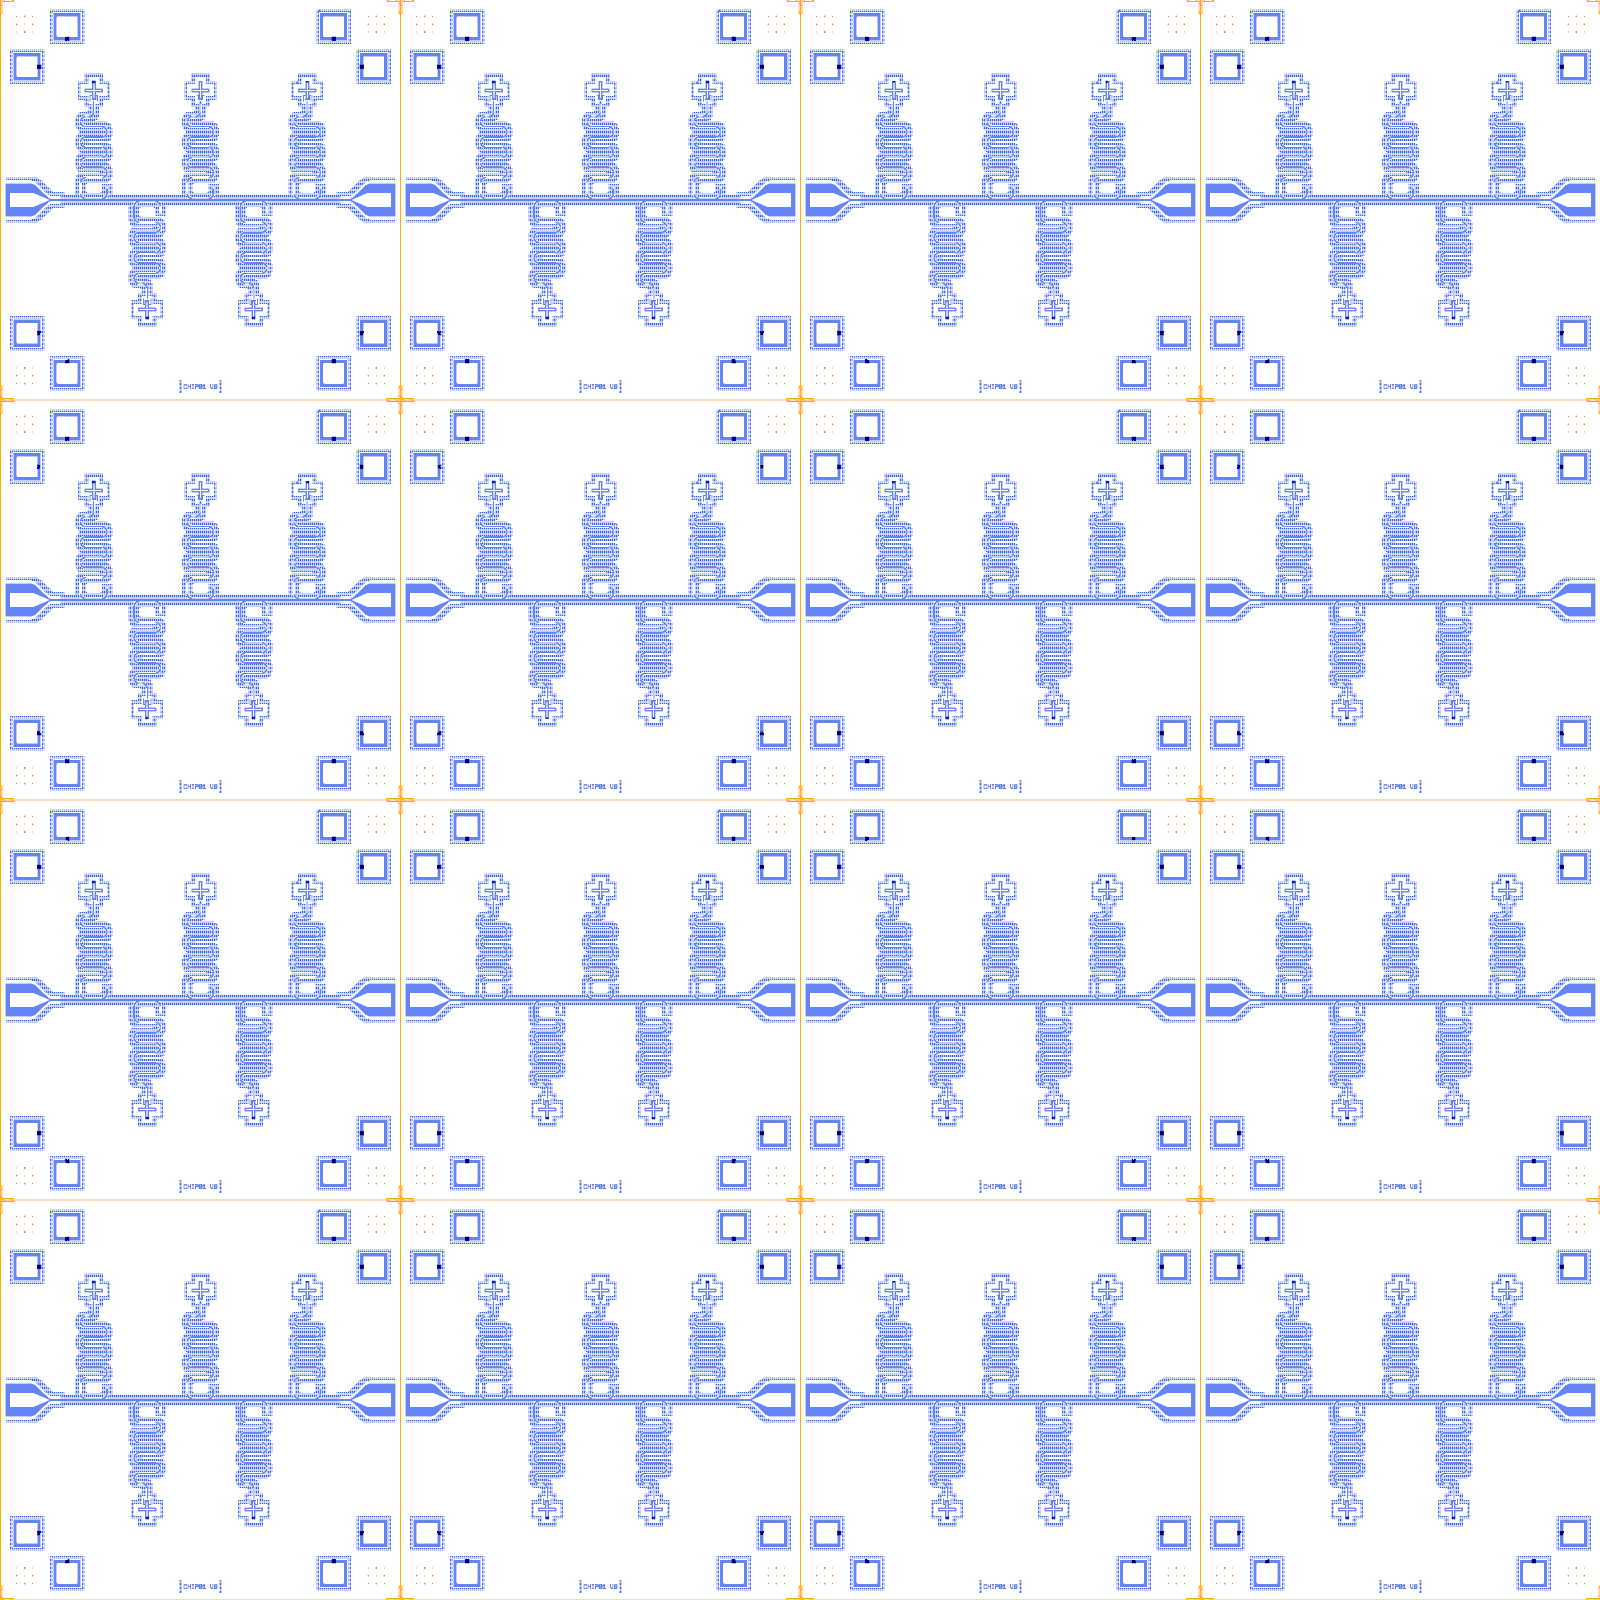

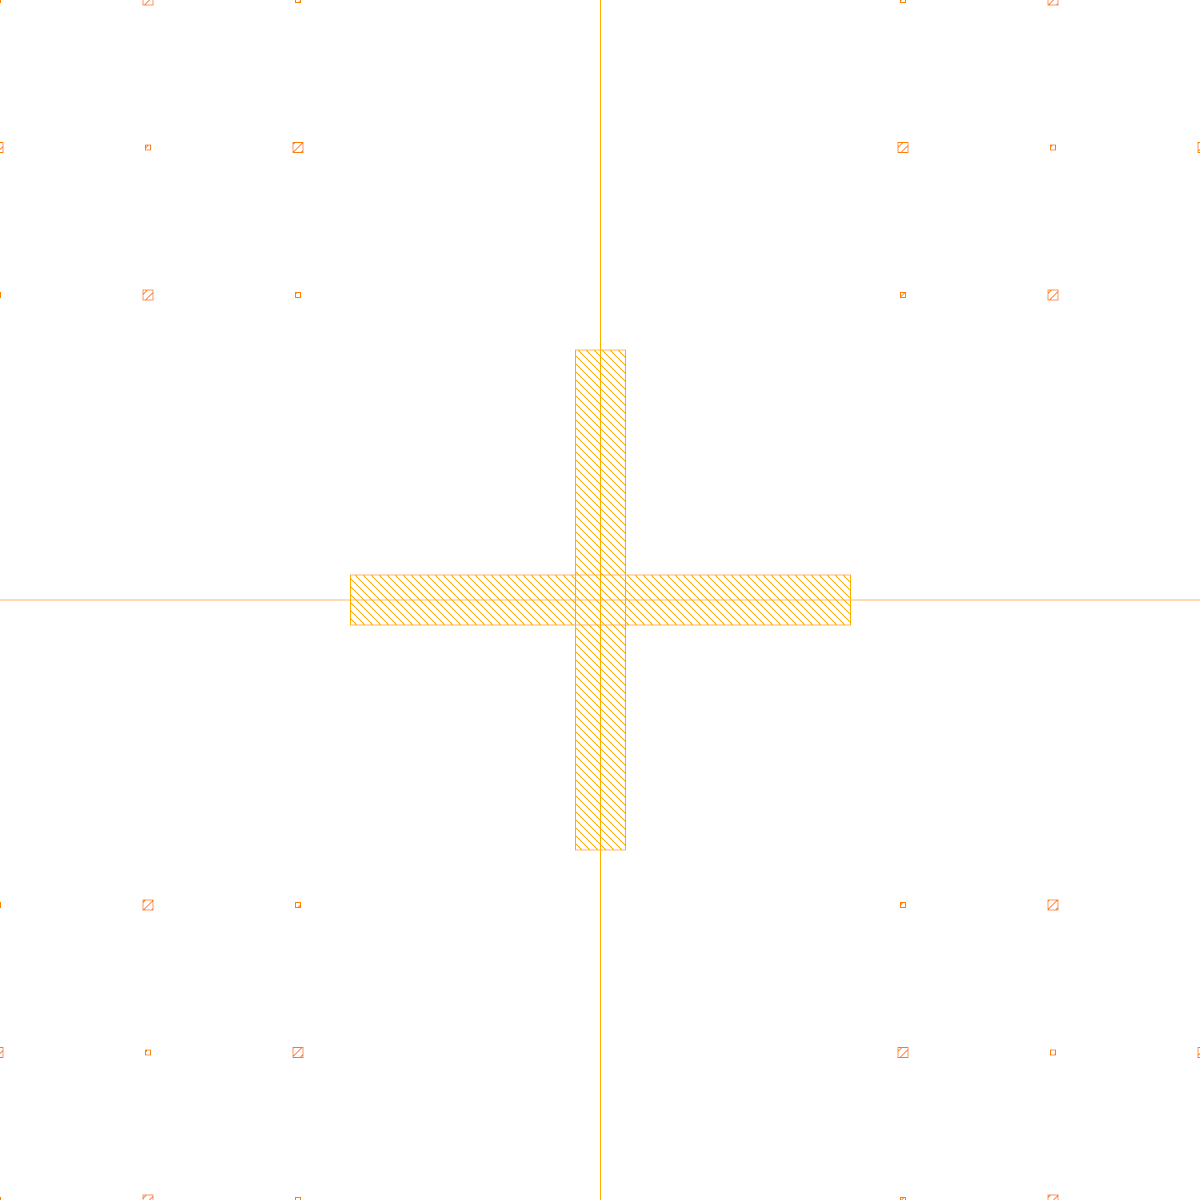

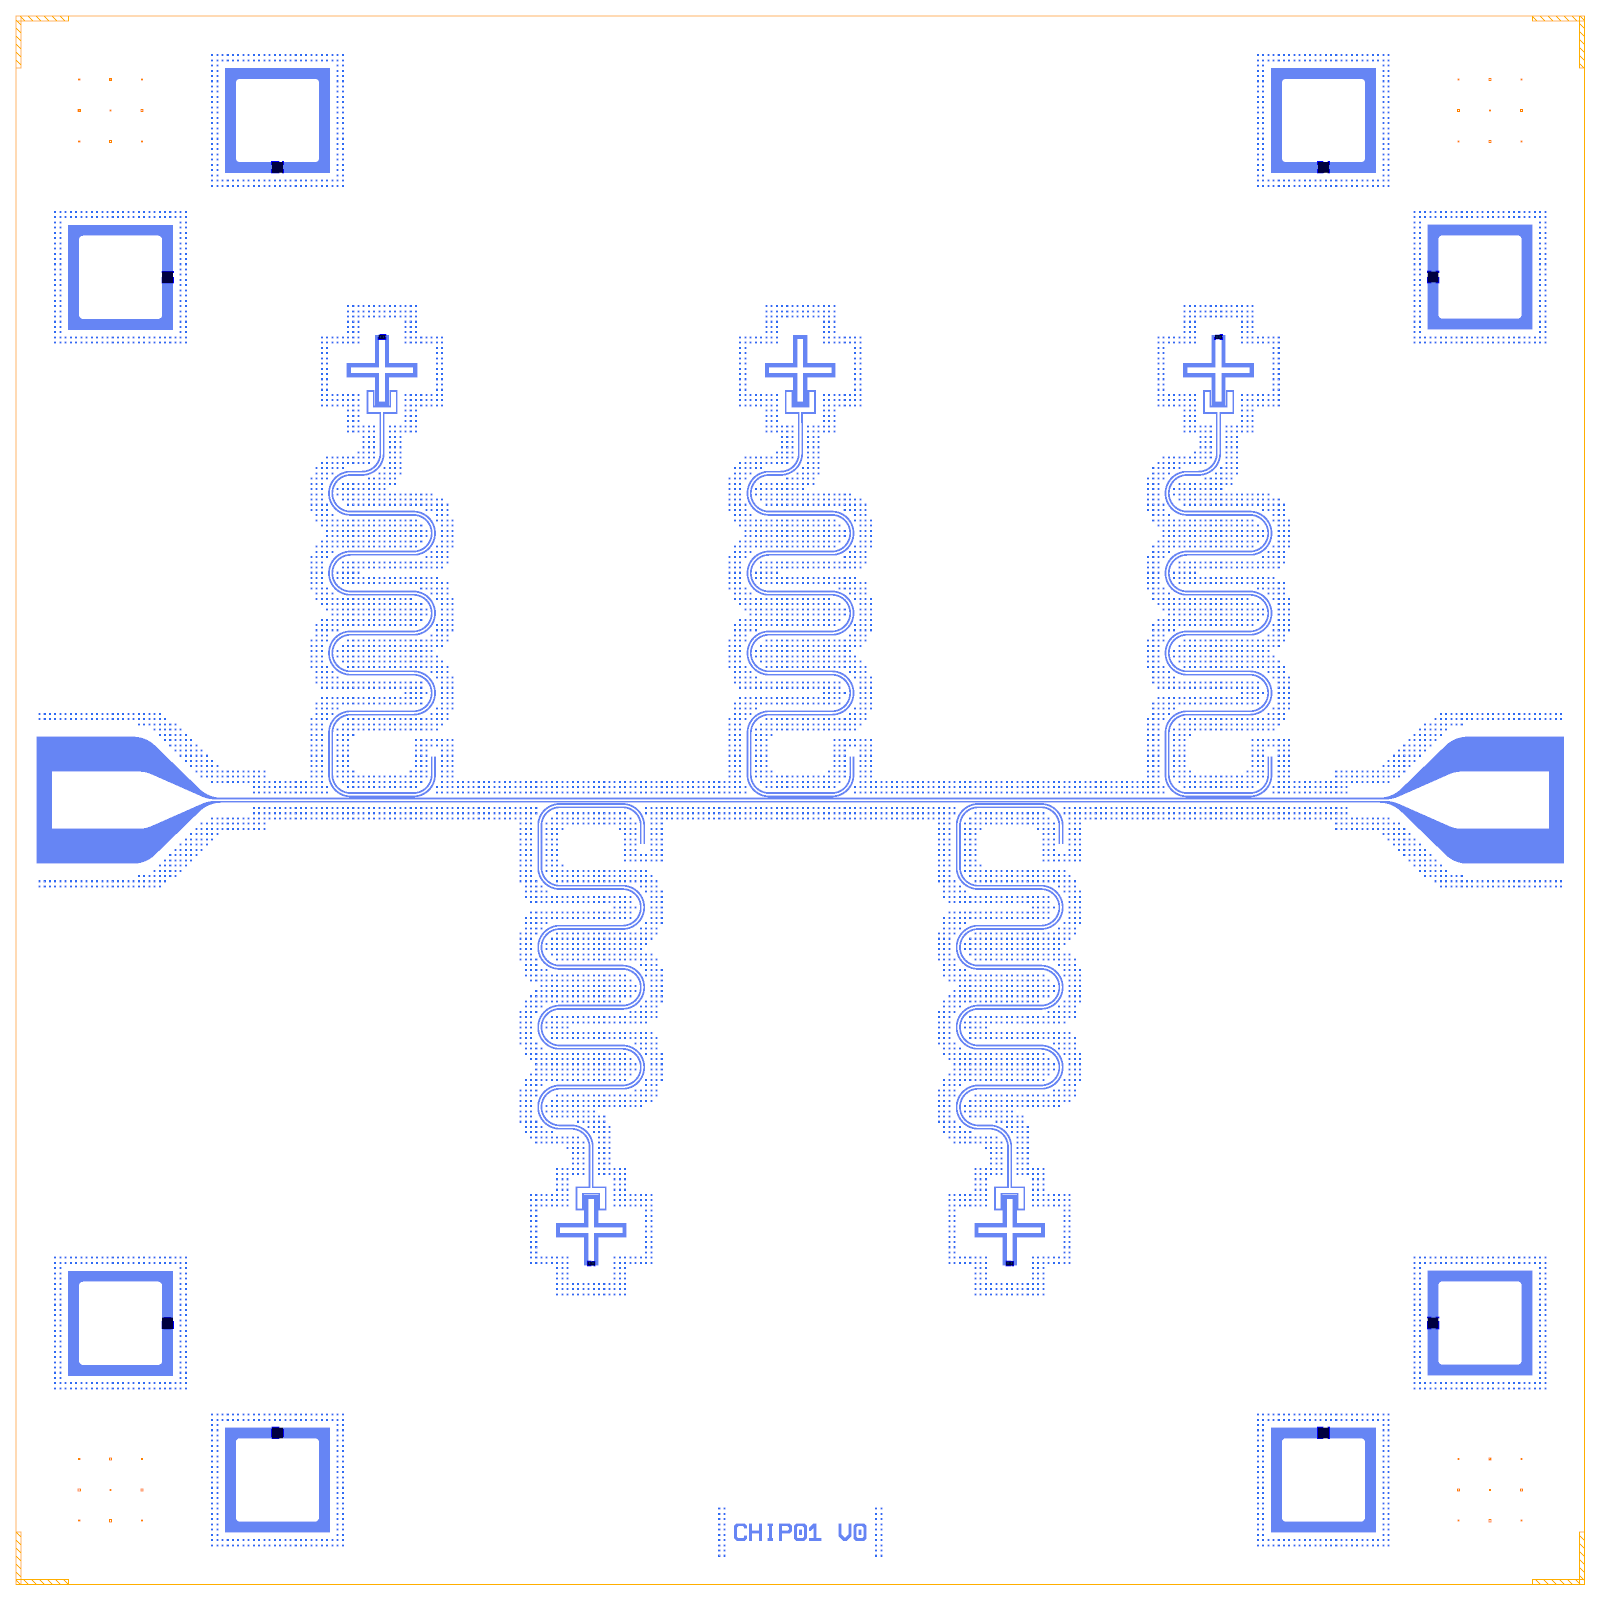

WindowsPath('examples/designs/legacy/chip_01_4x4_die.png')

In [15]:
from quantcore_circuits.live.snapshot import snapshot
snapshot(TILED, OUT / f"{ID}.png", size=(1600, 1600), box=(-15000, -15000, 15000, 15000))
display(Image(filename=str(OUT / f"{ID}.png"), width=640))
snapshot(TILED, OUT / f"{ID}_corner.png", size=(1200, 1200), box=(-600, -600, 600, 600))
display(Image(filename=str(OUT / f"{ID}_corner.png"), width=400))
C.show_snapshot(d, OUT / f"{ID}_die.png", width=480)

## 15 · Summary

- **Matches the source (fixed, #15):** sixteen chip_01 dies, one per 7.5 mm site at x, y ∈ {−11250, −3750, +3750,
  +11250} µm, 30 × 30 mm; the legacy script's 16 insertions on 4 overlapping sites are gone.
- **The die:** chip_01 as rebuilt in its notebook (`chip_01_4x4/die.json` regenerated from `chip_01.json` this
  pass): pads `pad_edge` = 100 µm from the die edge, PDK frame and device ID `CHIP01 V0`, PDK cheese band (fab
  cheese source "build", 9771 holes per die), `Quantcore Squid` × 4 at 45 kΩ; DRC clean, 0 PDK design warnings.
- **New:** the tiled fab mask `build/legacy_fix/chip_01_4x4_fab.oas` (the die's mask at the same sixteen sites).
- **Open (chip_01's):** the five resonators are degenerate (5.67 GHz); R1 at 4800 µm would move to 5.88 GHz
  (step 12).